In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [ ]:
df = pd.read_csv('smartcart_customers.csv')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


Data Preprocessing

In [ ]:
## 1 .)  Handel missing values 


df["Income"] = df["Income"].fillna(df["Income"].median())

In [ ]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

Feature Engineering

In [ ]:
# Age 

df["Age"] = 2026-df["Year_Birth"]

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


In [ ]:
# Customer Joinning Date 

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"] , dayfirst=True)

reference_date = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (reference_date -df["Dt_Customer"]).dt.days

In [ ]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [ ]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days'],
      dtype='str')

In [ ]:
# Spending 

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [ ]:
# Children 

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [ ]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [ ]:
# Education

df["Education"]  = df["Education"].replace({
    "Basic" : "Undergraduate" , "2n Cycle": "Undergraduate" ,
    "Graduation" : "Graduate" ,
    "Master" :  "Postgraduate" , "PhD" : "Postgraduate"
})

In [ ]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [ ]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [ ]:
# Marital_status 



df["Living_With"] = df["Marital_Status"].replace({
    "Married" : "Partner" , "Together" : "Partner" ,
    "Single" : "Alone" , "Divorced" : "Alone" , 
    "Widow" : "Alone" , "Absurd" : "Alone" , "YOLO" : "Alone"
})

In [ ]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

Drop columns 

In [ ]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Living_With'],
      dtype='str')

In [ ]:
cols = ["ID" , "Year_Birth" , "Marital_Status" , "Kidhome" , "Teenhome" , "Dt_Customer"]

spending_cols = ["MntWines", "MntFruits" , "MntMeatProducts" , "MntFishProducts" , "MntSweetProducts" , "MntGoldProds"]

cols_to_drop = cols + spending_cols
df_cleaned = df.drop(columns=cols_to_drop)

In [ ]:
df_cleaned.shape

(2240, 15)

In [ ]:
df.shape

(2240, 27)

In [ ]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


Outliers 

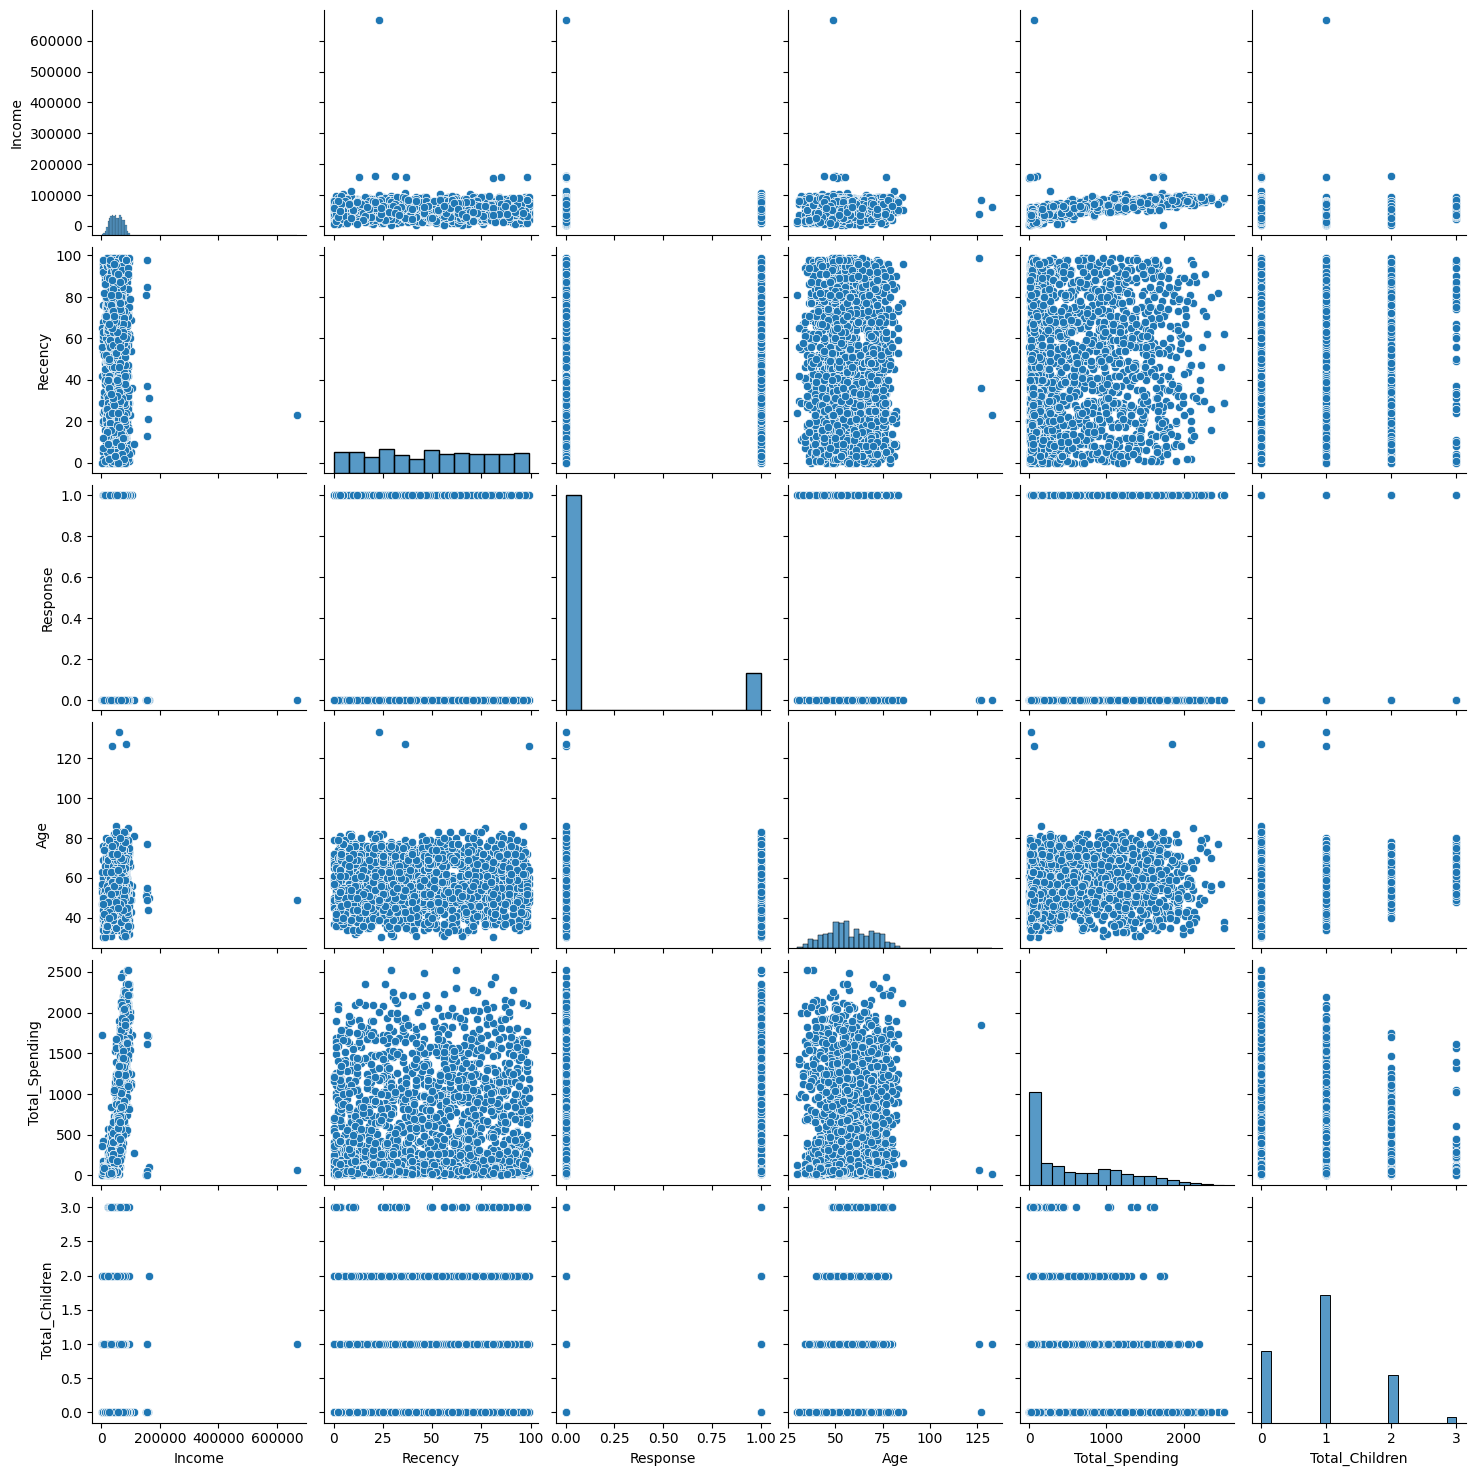

In [ ]:
cols = ["Income" , "Recency" , "Response" , "Age" , "Total_Spending" , "Total_Children"]

sns.pairplot(df_cleaned[cols])

In [ ]:
# Remove Outliers 


print ("data size with outliers:" , len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90)]

df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000)]

print ("data size wihout outliers :" , len(df_cleaned))

data size with outliers: 2240
data size wihout outliers : 2236


Heatmaps 

<Axes: >

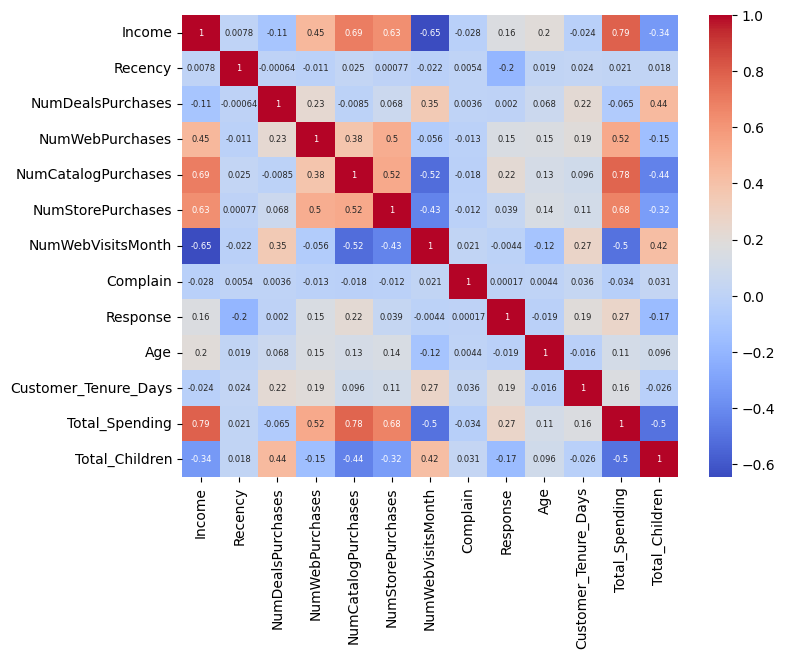

In [ ]:
corr = df_cleaned.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr ,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

# Encoding

In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
ohe = OneHotEncoder()

cat_cols = ["Education" , "Living_With"]
enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [ ]:
enc_df = pd.DataFrame(enc_cols.toarray() , columns=ohe.get_feature_names_out(cat_cols) , index=df_cleaned.index)

In [ ]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [ ]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols), enc_df] , axis=1)

In [ ]:
df_encoded.shape

(2236, 18)

In [ ]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


# Scaler 

In [ ]:
from sklearn.preprocessing import StandardScaler

x = df_encoded

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# Visualize

In [ ]:
x_scaled.shape

(2236, 18)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)

x_pca = pca.fit_transform(x_scaled)

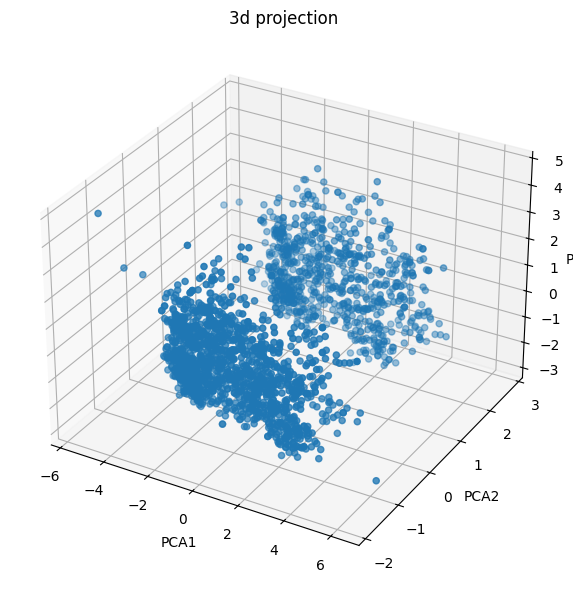

In [ ]:
# plot 

plt.close("all")
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111 , projection="3d")

ax.scatter(
    x_pca[:,0] ,
      x_pca[:,1] , 
      x_pca[:,2]
)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3d projection")
plt.tight_layout()
plt.show()

# Analyze K value 

1. Elbow method 

In [ ]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range (1,11):
    kmeans = KMeans(n_clusters=k , random_state=42)
    kmeans.fit_predict(x_pca)
    wcss.append(kmeans.inertia_)

In [ ]:
knee = KneeLocator(range(1,11), wcss , curve="convex" , direction="decreasing")
optimal_k = knee.elbow

In [ ]:
print ("best_k =" , optimal_k)

best_k = 4


Text(0, 0.5, 'WCSS')

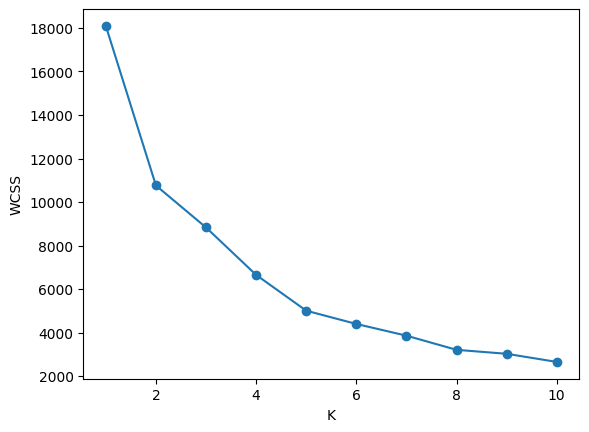

In [ ]:
# plot 

plt.plot(range(1,11) , wcss , marker='o')
plt.xlabel("K")
plt.ylabel("WCSS")

2. silhouette score 

Text(0, 0.5, 'Silhoutte Score')

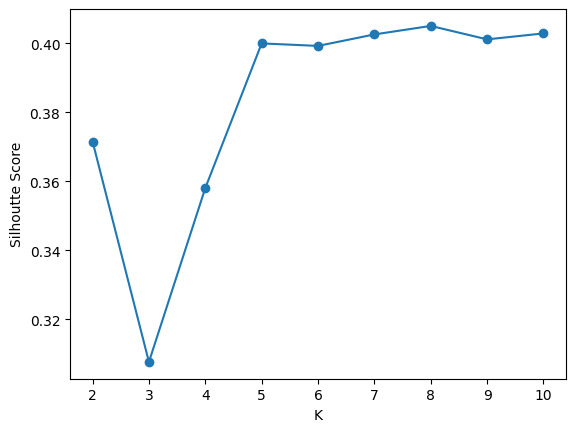

In [ ]:
from sklearn.metrics import silhouette_score

scores = []

for k1 in range (2,11):
    kmeanns = KMeans(n_clusters=k1 , random_state=42)
    labels = kmeanns.fit_predict(x_pca)
    score =silhouette_score(x_pca , labels)
    scores.append(score)


    
plt.Figure(figsize=(8,5))
plt.plot(range(2 , 11), scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhoutte Score")

Text(0, 0.5, 'ss')

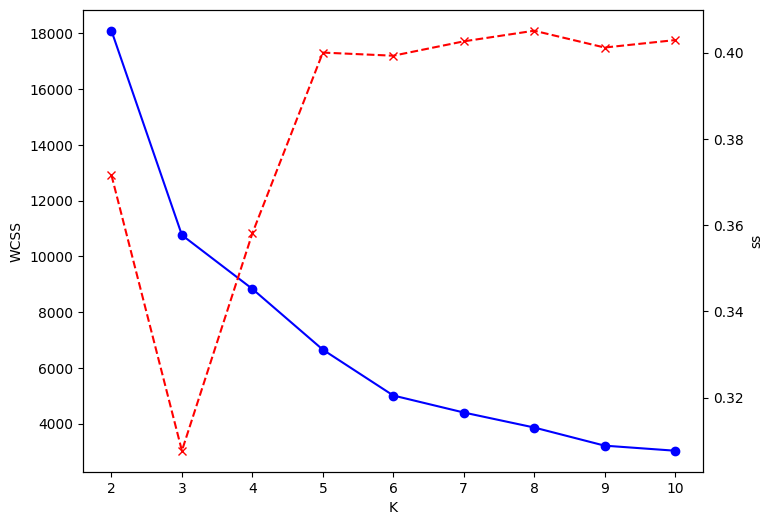

In [ ]:
# Combine Plot

k_range = range(2,11)

fig, ax1 = plt.subplots(figsize=(8, 6))
ax1.plot(k_range, wcss[:len(k_range)] , marker='o' , color="blue")

ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)] , marker='x' , color="red" , linestyle="--")
ax2.set_ylabel("ss")

# Clustering

K_Means

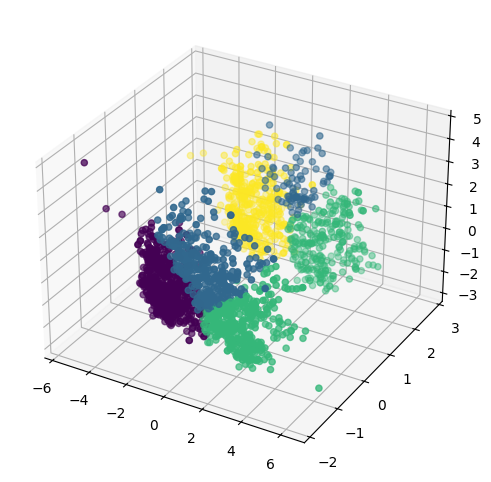

In [ ]:
kmeanss = KMeans(n_clusters=4 , random_state=42) 
labels_kmeans = kmeanss.fit_predict(x_pca)


plt.close("all")
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111 , projection="3d")

ax.scatter(
    x_pca[:,0] ,
      x_pca[:,1] , 
      x_pca[:,2], 
      c=labels_kmeans
)

Agglomerative clustering

In [ ]:
from sklearn.cluster import AgglomerativeClustering

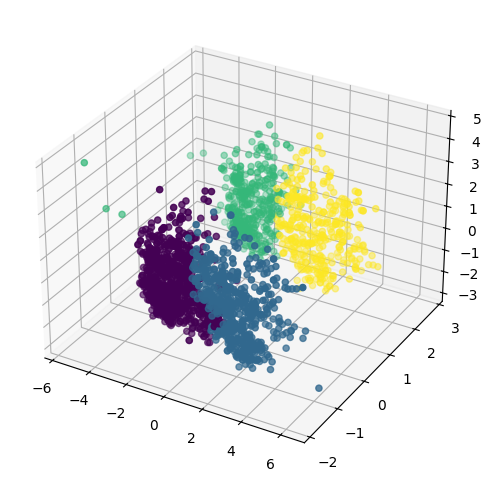

In [ ]:
agg_clf = AgglomerativeClustering(n_clusters=4 ,linkage="ward")
labels_agg = agg_clf.fit_predict(x_pca)

plt.close("all")
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111 , projection="3d")

ax.scatter(
    x_pca[:,0] ,
      x_pca[:,1] , 
      x_pca[:,2], 
      c=labels_agg
)

# Characterization of Cluster

In [ ]:
x["Clusters"] = labels_agg
x.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,Clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='Clusters', ylabel='count'>

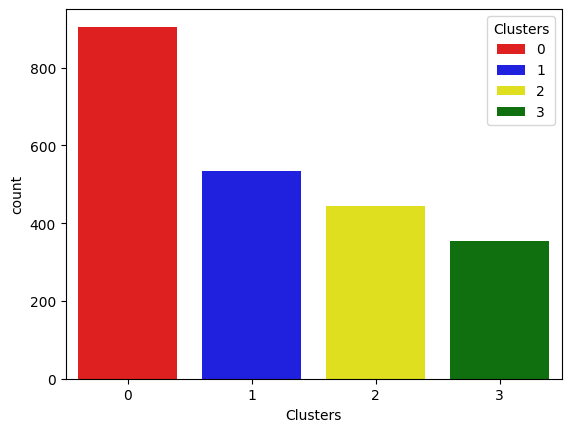

In [ ]:
pal = ["red" , "blue" , "yellow" , "green"]
sns.countplot(x=x["Clusters"] , palette=pal , hue=x["Clusters"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

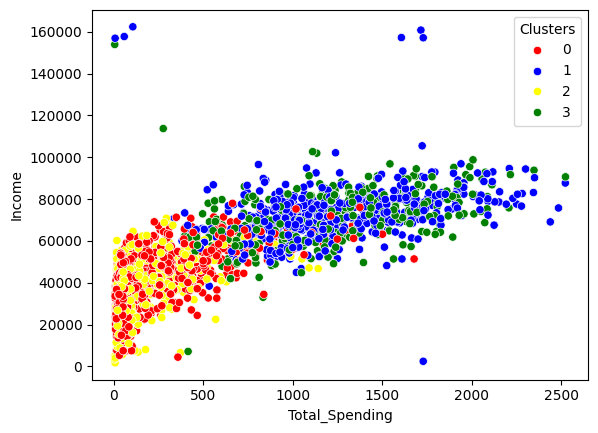

In [ ]:
# Income & spending patterns 

sns.scatterplot(x=x["Total_Spending"] , y=x["Income"] , hue=x["Clusters"] , palette=pal)

In [ ]:
# Cluster Summary

cluster_summary = x.groupby("Clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
Clusters                                                                
0         39680.580110  48.914917           2.594475         3.153591   
1         72808.445693  49.202247           1.958801         5.687266   
2         36960.143018  48.319820           2.594595         2.713964   
3         70722.681303  50.504249           1.855524         5.790368   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Clusters                                                                        
0                    0.969061           4.143646           6.307182  0.011050   
1                    5.498127           8.659176           3.580524  0.005618   
2                    0.837838           3.623874           6.659910  0.011261   
3                    5.014164           8.430595           3.728045  0.005666   

          Response        Age  Customer_Tenure_Days  Total_Spending  \
Clu